In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
TH99=0.14655972998295605
TH95=0.10024662155621214
# df must contain:
# patient_id, risk_t0, screen_date, event_date
# screen_date and event_date are integers on the same time scale
# event_date can be missing if event never occurred


plt.style.use('fivethirtyeight')

def make_km_plot(
    df,
    screen_col="screen_date",
    event_col="event_date",
    risk_col="risk_t0",
    max_followup=5,
    risk_split="median",   # "median", numeric threshold, or None
    title="Kaplan-Meier curve",
    time_unit_label="Time since screening"
):
    d = df.copy()

    # Coerce to numeric
    d[screen_col] = pd.to_numeric(d[screen_col], errors="coerce")
    d[event_col] = pd.to_numeric(d[event_col], errors="coerce")
    d[risk_col] = pd.to_numeric(d[risk_col], errors="coerce")

    # Drop rows with invalid screening time or missing risk
    d = d[d[screen_col].notna() & d[risk_col].notna()].copy()

    # Time from screening to event
    time_to_event = d[event_col] - d[screen_col]

    # Event observed only if:
    #   event exists
    #   event_date >= screen_date
    #   event occurs within follow-up window
    d["event_observed"] = (
        d[event_col].notna() &
        (d[event_col] >= d[screen_col]) &
        (time_to_event <= max_followup)
    ).astype(int)

    # Observed time:
    # actual time if valid observed event, otherwise censor at max_followup
    d["time"] = np.where(
        d["event_observed"] == 1,
        time_to_event,
        max_followup
    )

    # Remove negative observed/censor times if any weird rows remain
    d = d[d["time"] >= 0].copy()

    plt.figure(figsize=(8, 6))
    kmf = KaplanMeierFitter()

    if risk_split == "median":
        thr = d[risk_col].median()
        d["risk_group"] = np.where(d[risk_col] >= thr, "High risk", "Low risk")

        for grp in ["High risk", "Low risk"]:
            sub = d[d["risk_group"] == grp]
            if len(sub) == 0:
                continue
            kmf.fit(
                durations=sub["time"],
                event_observed=sub["event_observed"],
                label=f"{grp} (n={len(sub)})"
            )
            kmf.plot_survival_function(ci_show=True)

        plt.title(f"{title}\nSplit at median {risk_col} = {thr:.4f}")

    elif isinstance(risk_split, (int, float)):
        thr = float(risk_split)
        d["risk_group"] = np.where(d[risk_col] >= thr, "High risk", "Low risk")

        for grp in ["High risk", "Low risk"]:
            sub = d[d["risk_group"] == grp]
            if len(sub) == 0:
                continue
            kmf.fit(
                durations=sub["time"],
                event_observed=sub["event_observed"],
                label=f"{grp} (n={len(sub)})"
            )
            kmf.plot_survival_function(ci_show=True)

        plt.title(f"{title}\nSplit at {risk_col} = {thr:.4f}")

    else:
        kmf.fit(
            durations=d["time"],
            event_observed=d["event_observed"],
            label="All patients"
        )
        kmf.plot_survival_function(ci_show=True)
        plt.title(title)

    plt.xlim(0, max_followup)
    plt.xlabel(time_unit_label)
    plt.ylabel("Event-free survival probability")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return d


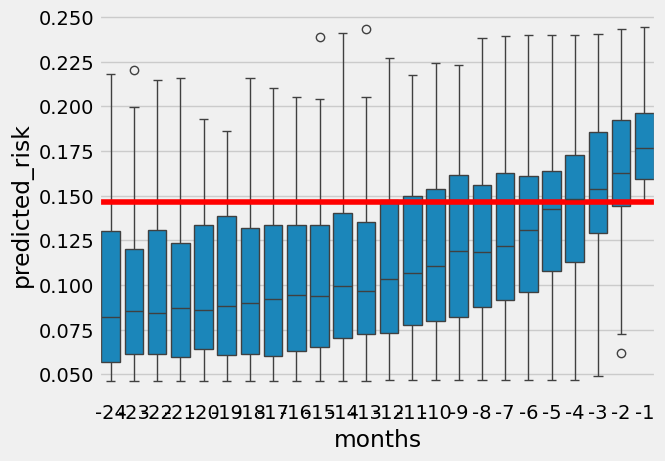

In [2]:
import pandas as pd
import seaborn as sns
import pylab as plt
df=pd.read_csv('./violin_plots_data.csv')
sns.boxplot(data=df,x='months',y='predicted_risk')
plt.axhline(0.14655972998295605,c='r')

In [3]:
import pandas as pd
import numpy as np

def make_screen_event_df_all(
    df,
    risk_threshold,
    patient_col="patient_id",
    month_col="months",
    risk_col="predicted_risk",
):
    df = df.copy()
    df = df.sort_values([patient_col, month_col])

    rows = []

    for pid, g in df.groupby(patient_col, sort=False):
        g = g.sort_values(month_col).reset_index(drop=True)

        crossed = g[g[risk_col] > risk_threshold]

        if crossed.empty:
            continue

        first_idx = crossed.index[0]

        screen_date = g.loc[first_idx, month_col]
        risk_crossing = g.loc[first_idx, risk_col]

        if first_idx > 0:
            risk_prev = g.loc[first_idx - 1, risk_col]
        else:
            risk_prev = np.nan

        delta_1 = risk_crossing - risk_prev if pd.notna(risk_prev) else np.nan

        rows.append({
            "patient_id": pid,
            "screen_date": screen_date,
            "event_date": -1,
            "risk_crossing": risk_crossing,
            "risk_prev": risk_prev,
            "delta_1": delta_1
        })

    return pd.DataFrame(rows)

def add_dynamic_risk_score(df):
    df = df.copy()

    rc = df["risk_crossing"]
    d1 = df["delta_1"]

    rc_z = (rc - rc.mean()) / rc.std()
    d1_z = (d1 - d1.mean()) / d1.std()

    df["risk_dynamic"] = rc_z + d1_z

    return df    




def redefine_risk_with_delta(
    df,
    level_col="risk_crossing",
    delta_col="delta_1",
    alpha=1.0,
):
    """
    Redefine risk_crossing to depend on both level and increase.

    new risk_crossing =
        z(level) + alpha * z(delta)

    alpha controls how strongly recent increase influences risk.
    alpha = 1.0 gives equal weight.
    """

    d = df.copy()

    d.risk_crossing = 0*(d.risk_prev) + 1*d.risk_crossing

    return d

In [4]:
df_=make_screen_event_df_all(df,risk_threshold=TH99)
df_['event_date'] = df_.event_date-df_.screen_date
df_.screen_date = 0
#df_=df_.fillna(0)
#df_['newrisk'] = df_.risk_crossing/df_.delta_1
df_

,patient_id,screen_date,event_date,risk_crossing,risk_prev,delta_1
0,1.018601e+06,0,0,0.149543,0.127247,0.022296
1,2.778300e+07,0,4,0.164255,0.103837,0.060418
2,1.396464e+08,0,20,0.160798,0.146397,0.014401
3,2.126150e+08,0,0,0.159715,0.117652,0.042063
4,5.350068e+08,0,23,0.177268,NaN,NaN
...,...,...,...,...,...,...
99,3.190233e+10,0,5,0.152709,0.084557,0.068152
100,3.190311e+10,0,8,0.157316,0.100319,0.056998
101,3.190329e+10,0,0,0.199062,0.104453,0.094609
102,3.194395e+10,0,12,0.150285,0.114721,0.035564


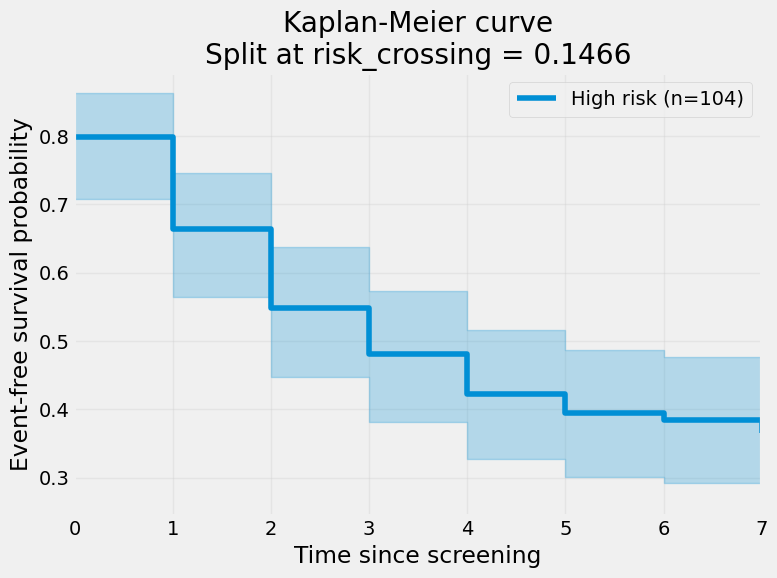

<Figure size 640x480 with 0 Axes>

In [5]:
processed_df=make_km_plot(
    df_,
    screen_col="screen_date",
    event_col="event_date",
    risk_col="risk_crossing",
    max_followup=7,
    risk_split=TH99,#"median",   # "median", numeric threshold, or None
    title="Kaplan-Meier curve")
plt.savefig('survival.png',dpi=300,bbox_inches='tight',transparent=True)

In [6]:

from lifelines import CoxPHFitter

def prepare_survival_data(
    df,
    screen_col="screen_date",
    event_col="event_date",
    risk_col="risk_t0",
    patient_col="patient_id",
    max_followup=5,
):
    """
    Standardize a screening/event table into a survival-analysis-ready frame.

    Returns a copy with:
      - time: observed follow-up time
      - event_observed: 1 if event occurred within the follow-up window, else 0
    """
    d = df.copy()

    d[screen_col] = pd.to_numeric(d[screen_col], errors="coerce")
    d[event_col] = pd.to_numeric(d[event_col], errors="coerce")
    d[risk_col] = pd.to_numeric(d[risk_col], errors="coerce")

    keep_cols = [screen_col, risk_col]
    if patient_col in d.columns:
        keep_cols.append(patient_col)

    d = d[d[screen_col].notna() & d[risk_col].notna()].copy()

    time_to_event = d[event_col] - d[screen_col]

    d["event_observed"] = (
        d[event_col].notna()
        & (d[event_col] >= d[screen_col])
        & (time_to_event <= max_followup)
    ).astype(int)

    d["time"] = np.where(d["event_observed"] == 1, time_to_event, max_followup)
    d = d[d["time"] >= 0].copy()

    return d


def fit_individual_hazard_model(
    df,
    covariate_cols,
    screen_col="screen_date",
    event_col="event_date",
    patient_col="patient_id",
    max_followup=5,
    penalizer=0.1,
):
    """
    Fit a Cox proportional hazards model and return:
      - fitted CoxPHFitter object
      - processed dataframe used for fitting
    """
    d = df.copy()

    for c in covariate_cols:
        d[c] = pd.to_numeric(d[c], errors="coerce")

    d = prepare_survival_data(
        d,
        screen_col=screen_col,
        event_col=event_col,
        risk_col=covariate_cols[0],
        patient_col=patient_col,
        max_followup=max_followup,
    )

    fit_cols = ["time", "event_observed"] + covariate_cols
    if patient_col in d.columns:
        fit_cols = [patient_col] + fit_cols

    fit_df = d[fit_cols].dropna().copy()

    cph = CoxPHFitter(penalizer=penalizer)
    cph.fit(
        fit_df.drop(columns=[patient_col], errors="ignore"),
        duration_col="time",
        event_col="event_observed",
    )

    return cph, fit_df


def estimate_individual_hazards(
    cph,
    fit_df,
    covariate_cols,
    patient_col="patient_id",
):
    """
    Estimate subject-specific hazard and cumulative hazard curves.

    Uses:
      h_i(t) = h0(t) * exp(x_i beta)
      H_i(t) = H0(t) * exp(x_i beta)

    Returns a long dataframe with columns:
      patient_id, time, hazard, cumulative_hazard, survival, partial_hazard
    """
    if cph.baseline_hazard_ is None or cph.baseline_cumulative_hazard_ is None:
        raise ValueError("Model has no estimated baseline hazard. Fit the Cox model first.")

    base_h = cph.baseline_hazard_.iloc[:, 0]
    base_H = cph.baseline_cumulative_hazard_.iloc[:, 0]

    partial_pred = cph.predict_partial_hazard(fit_df[covariate_cols])

    # lifelines may return either a Series or a single-column DataFrame
    if isinstance(partial_pred, pd.DataFrame):
        partial_hz = partial_pred.iloc[:, 0]
    else:
        partial_hz = pd.Series(partial_pred, index=fit_df.index, name="partial_hazard")

    out = []

    if patient_col in fit_df.columns:
        ids = fit_df[patient_col].values
    else:
        ids = np.arange(len(fit_df))

    for pid, ph in zip(ids, partial_hz.values):
        hazard_i = base_h * ph
        cumhaz_i = base_H * ph
        surv_i = np.exp(-cumhaz_i)

        tmp = pd.DataFrame({
            patient_col: pid,
            "time": base_h.index.values,
            "hazard": hazard_i.values,
            "cumulative_hazard": cumhaz_i.values,
            "survival": surv_i.values,
            "partial_hazard": ph,
        })
        out.append(tmp)

    return pd.concat(out, ignore_index=True)


def plot_individual_hazards(
    hazard_df,
    patient_ids=None,
    patient_col="patient_id",
    value_col="hazard",
    top_n=10,
    figsize=(9, 6),
    title=None,
):
    """
    Plot subject-specific hazard-type curves.

    value_col can be:
      - 'hazard'
      - 'cumulative_hazard'
      - 'survival'
    """
    valid = {"hazard", "cumulative_hazard", "survival"}
    if value_col not in valid:
        raise ValueError(f"value_col must be one of {valid}")

    d = hazard_df.copy()

    if patient_ids is not None:
        d = d[d[patient_col].isin(patient_ids)].copy()
    else:
        ranking = (
            d.groupby(patient_col)["partial_hazard"]
            .first()
            .sort_values(ascending=False)
            .head(top_n)
            .index
        )
        d = d[d[patient_col].isin(ranking)].copy()

    plt.figure(figsize=figsize)
    for pid, g in d.groupby(patient_col):
        g = g.sort_values("time")
        plt.step(g["time"], g[value_col], where="post", label=str(pid), alpha=0.85)

    ylabel_map = {
        "hazard": "Estimated hazard",
        "cumulative_hazard": "Estimated cumulative hazard",
        "survival": "Estimated survival",
    }

    if title is None:
        title = f"Individual {value_col.replace('_', ' ')} curves"

    plt.title(title)
    plt.xlabel("Time since screening")
    plt.ylabel(ylabel_map[value_col])
    plt.grid(True, alpha=0.3)
    plt.legend(title=patient_col, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


def summarize_individual_hazards(
    hazard_df,
    patient_col="patient_id",
):
    """
    One-row-per-patient summary for quick ranking / inspection.
    """
    summary = (
        hazard_df.groupby(patient_col)
        .agg(
            partial_hazard=("partial_hazard", "first"),
            final_cumulative_hazard=("cumulative_hazard", "last"),
            final_survival=("survival", "last"),
            peak_hazard=("hazard", "max"),
        )
        .sort_values("partial_hazard", ascending=False)
        .reset_index()
    )
    return summary


,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
covariate,,,,,,,,,,,
risk_crossing,8.785202,6536.794224,6.393135,-3.745112,21.315517,0.023633,1.808054e+09,0.0,1.374162,0.169391,2.561567


,patient_id,partial_hazard,final_cumulative_hazard,final_survival,peak_hazard
0,2.799689e+10,1.651025,1.539872,0.214409,0.329654
1,1.263524e+09,1.579131,1.472818,0.229278,0.315299
2,8.503782e+08,1.467908,1.369082,0.254340,0.293091
3,3.190329e+10,1.334985,1.245109,0.287910,0.266551
4,2.828669e+10,1.325727,1.236474,0.290407,0.264703
5,1.260075e+09,1.325222,1.236002,0.290543,0.264602
6,1.783575e+09,1.283455,1.197048,0.302085,0.256262
7,2.222206e+09,1.281478,1.195203,0.302642,0.255867
8,1.859167e+09,1.265271,1.180088,0.307252,0.252632
9,2.755951e+10,1.235126,1.151972,0.316013,0.246613


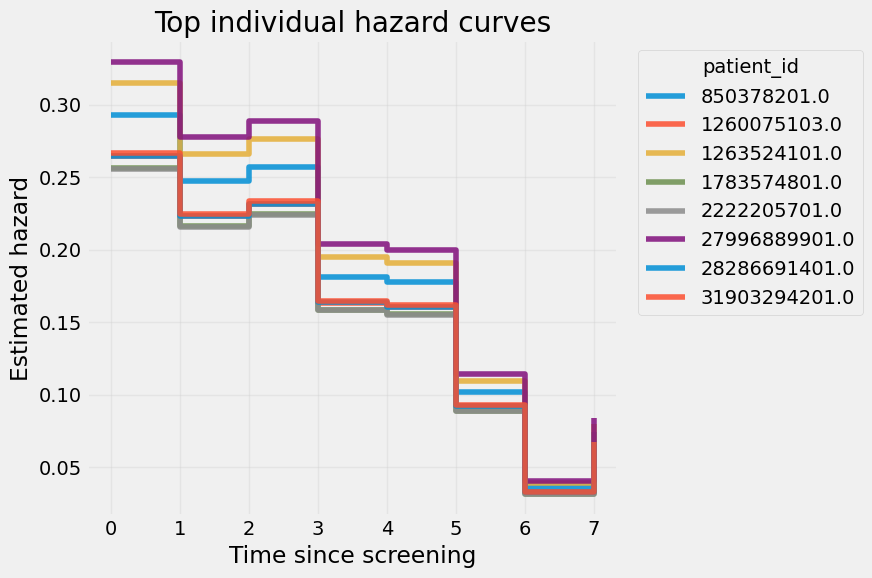

<Figure size 640x480 with 0 Axes>

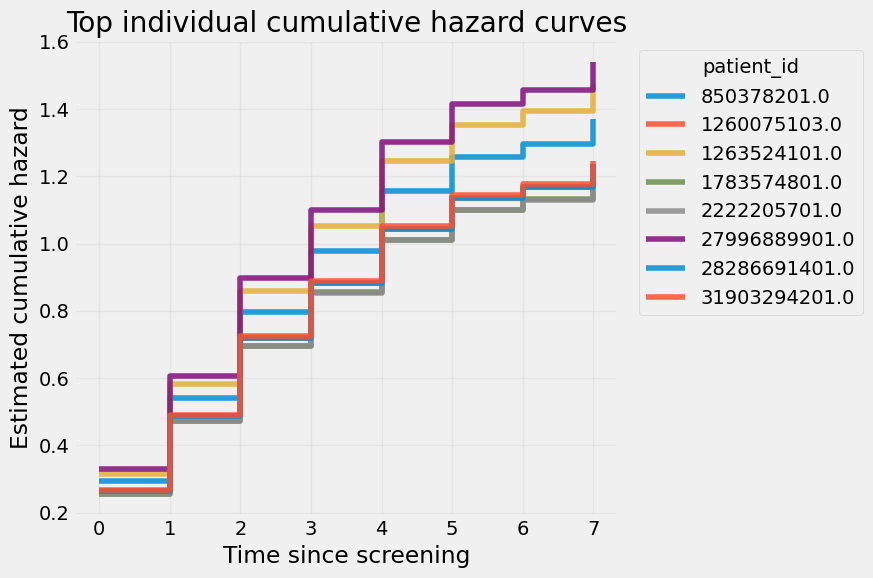

<Figure size 640x480 with 0 Axes>

In [9]:

# Example: fit a subject-specific hazard model from the processed screening table

cph, fit_df = fit_individual_hazard_model(
    df_,
    covariate_cols=["risk_crossing"],   # you can also try ["risk_crossing", "delta_1"]
    screen_col="screen_date",
    event_col="event_date",
    patient_col="patient_id",
    max_followup=7,
    penalizer=0.1,
)

display(cph.summary)

hazard_df = estimate_individual_hazards(
    cph,
    fit_df,
    covariate_cols=["risk_crossing"],
    patient_col="patient_id",
)

hazard_summary = summarize_individual_hazards(hazard_df)
display(hazard_summary.head(10))

plot_individual_hazards(
    hazard_df,
    value_col="hazard",
    top_n=8,
    title="Top individual hazard curves",
)
plt.savefig('individual_hazard.png',dpi=300,bbox_inches='tight',transparent=True)
plot_individual_hazards(
    hazard_df,
    value_col="cumulative_hazard",
    top_n=8,
    title="Top individual cumulative hazard curves",
)
plt.savefig('individual_cumulative_hazard.png',dpi=300,bbox_inches='tight',transparent=True)